# Tutorial 6: Neighbors, Adjacency, and Spatial Queries

Models on meshes need two kinds of lookup. Graph neural networks pass messages
between neighbors in the mesh connectivity. Training pipelines evaluate fields
at points that are not mesh points, such as random samples or sensor
locations. This tutorial covers both, with GPU tensors and no Python loops
over cells.

**What You Will Build**: the edge graph of a mesh, with edge features and one
message-passing step, plus the queries that locate, sample, and measure the
distance to any point.

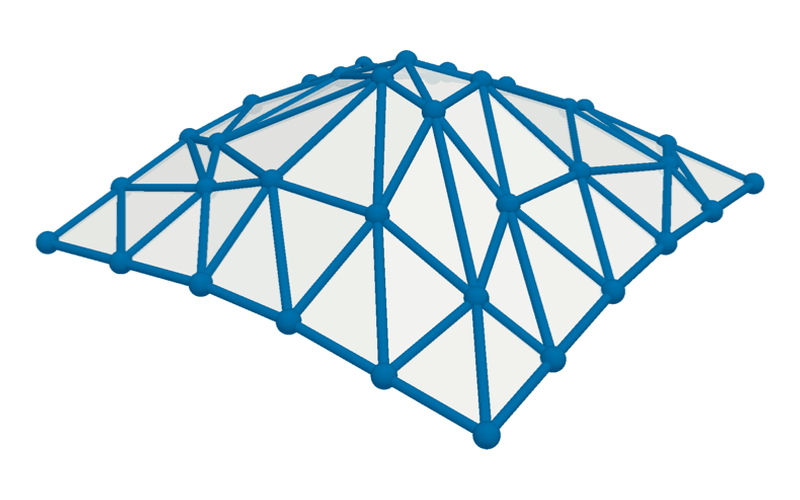

In [1]:
from IPython.display import Image

Image(filename="../../../docs/img/mesh/thumbnails/graphs.png", width=400)

You will learn:

- The four adjacency queries, and how the `Adjacency` class stores their
  ragged results.
- Why every mesh is one call away from a graph, a `Mesh[1, n]`, and how to
  pass messages on it with plain tensors.
- How to locate points in cells, sample and interpolate fields, and compute
  the signed distance to a surface.

Prerequisites: [Tutorial 1](tutorial_1_getting_started.ipynb) (the `Mesh` data
model) and [Tutorial 4](tutorial_4_operations.ipynb) (facets and edge graphs).
The notebook runs on a CPU in a few seconds, and uses a GPU when one is
present.

In [2]:
import matplotlib.pyplot as plt
import torch

from physicsnemo.mesh import Mesh
from physicsnemo.mesh.primitives.planar import unit_square
from physicsnemo.mesh.primitives.surfaces import sphere_icosahedral
from physicsnemo.mesh.sampling import (
    find_all_containing_cells,
    find_containing_cells,
    find_nearest_cells,
)
from physicsnemo.mesh.spatial import BVH, signed_distance_field

torch.set_printoptions(precision=4, sci_mode=False)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


## 1. Topological Neighbors

Topological neighbors share a part of the mesh. Two points are neighbors when
an edge joins them, and two cells are neighbors when they share a facet. The
distance between them does not matter. The mesh offers four queries:

| Method | For Each | Returns |
|---|---|---|
| `get_point_to_points_adjacency()` | point | the points joined to it by an edge |
| `get_point_to_cells_adjacency()` | point | the cells that contain it (its star) |
| `get_cell_to_cells_adjacency()` | cell | the cells that share a facet with it |
| `get_cell_to_points_adjacency()` | cell | its vertices |

The figure shows each query on a small triangle mesh. The query element is
orange, and its neighbors are blue:

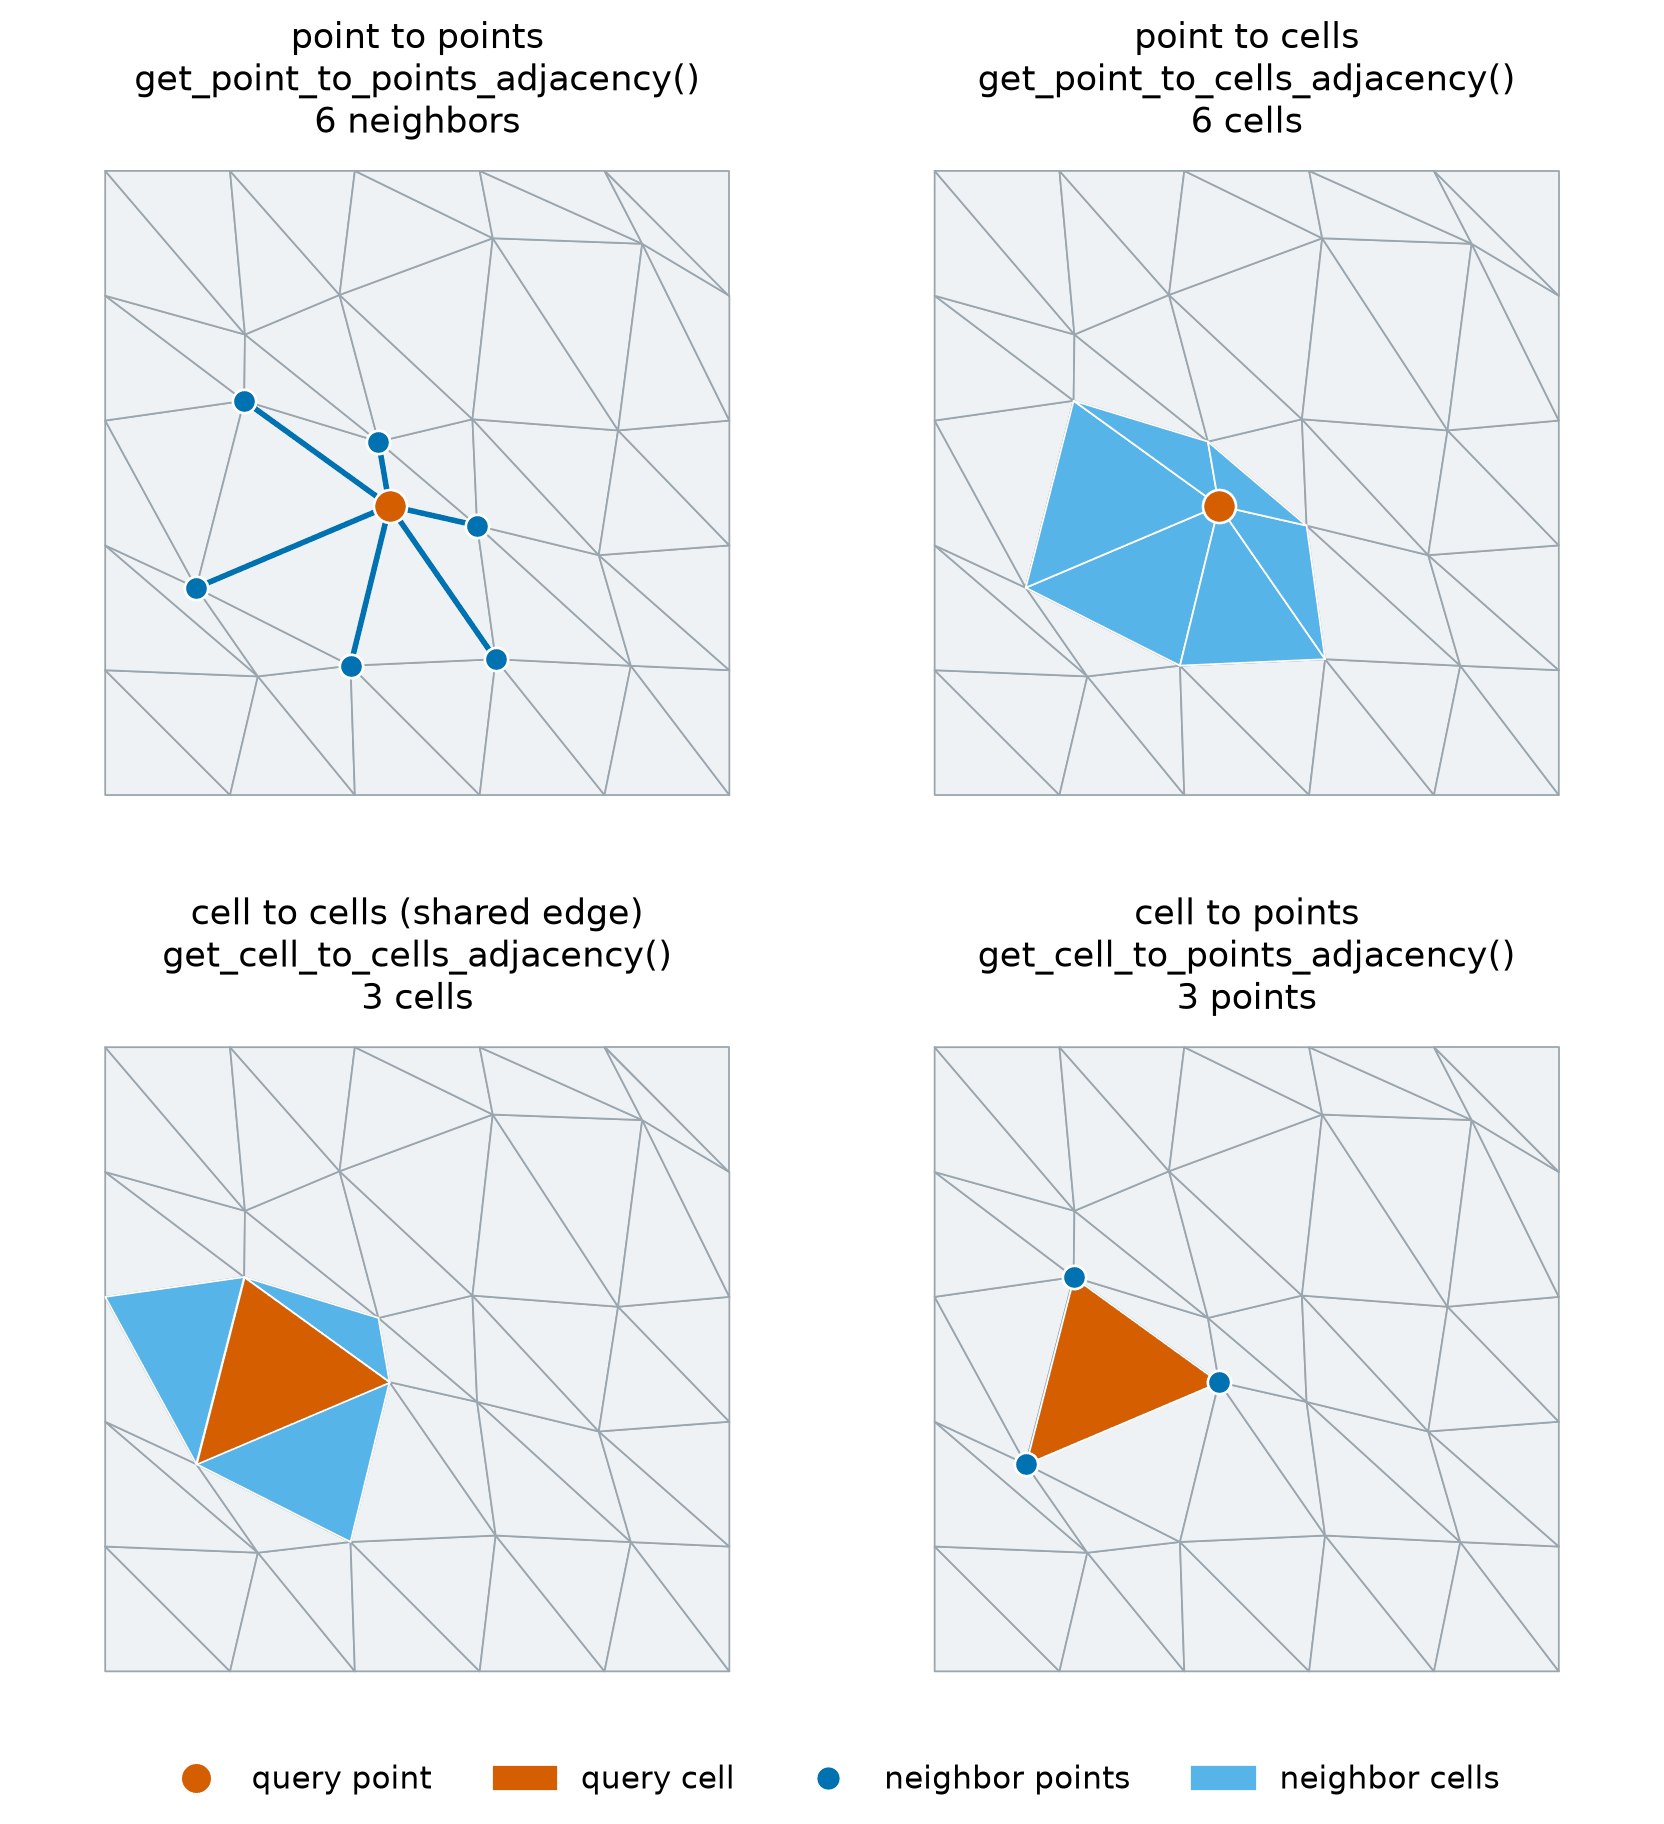

In [3]:
Image(filename="../../../docs/img/mesh/neighbors_adjacency.png", width=600)

Each query returns the neighbors of every element at once. On a closed
surface, the counts show the structure of the mesh. Each point of an
icosahedral sphere has five or six neighbors. The 12 points of the original
icosahedron have five, and all points added by subdivision have six:

In [4]:
sphere = sphere_icosahedral.load(subdivisions=1, device=device)
point_neighbors = sphere.get_point_to_points_adjacency()
valence, count = point_neighbors.counts.unique(return_counts=True)
print(f"Mesh: {sphere}")
print(f"Neighbors of point 0: {point_neighbors.to_list()[0]}")
print(f"Points with 5 or 6 neighbors: {dict(zip(valence.tolist(), count.tolist()))}")

Mesh: Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=42, n_cells=80)
Neighbors of point 0: [12, 13, 14, 15, 16]
Points with 5 or 6 neighbors: {5: 12, 6: 30}


`get_cell_to_cells_adjacency` takes an `adjacency_codimension`. The default, 1,
counts cells that share a facet (an edge, for triangles). A value of 2 counts
cells that share a facet of the facets, which for triangles means any shared
point.

In [5]:
for codimension in [1, 2]:
    adjacency = sphere.get_cell_to_cells_adjacency(adjacency_codimension=codimension)
    counts, n_cells = adjacency.counts.unique(return_counts=True)
    print(
        f"adjacency_codimension={codimension}: {dict(zip(counts.tolist(), n_cells.tolist()))}"
    )

adjacency_codimension=1: {3: 80}
adjacency_codimension=2: {11: 60, 12: 20}


## 2. The Adjacency Data Structure

The number of neighbors differs from element to element, so the result is a
ragged list. A tensor cannot hold a ragged list directly. The `Adjacency`
class stores it in two flat tensors, as in the compressed sparse row (CSR)
format of sparse matrices:

- `indices` holds all neighbor lists, one after the other.
- `offsets` holds the start of each list in `indices`, plus a final entry
  equal to `len(indices)`. The neighbors of element `i` are
  `indices[offsets[i]:offsets[i + 1]]`.

`counts` gives the length of each list, and `to_list()` gives a Python list of
lists. Use `to_list()` only for inspection, because it copies everything to
the host.

In [6]:
i = 5
start, end = point_neighbors.offsets[i].item(), point_neighbors.offsets[i + 1].item()
print(f"offsets: shape {tuple(point_neighbors.offsets.shape)}")
print(f"indices: shape {tuple(point_neighbors.indices.shape)}")
print(
    f"Neighbors of point {i}, from the tensors: {point_neighbors.indices[start:end].tolist()}"
)
print(f"Neighbors of point {i}, from to_list():  {point_neighbors.to_list()[i]}")

offsets: shape (43,)
indices: shape (240,)
Neighbors of point 5, from the tensors: [13, 17, 30, 33, 34]
Neighbors of point 5, from to_list():  [13, 17, 30, 33, 34]


The `offsets` tensor is always `int64`. For point to points and cell to points,
`indices` has the integer type of `mesh.cells`. This keeps the memory of a
mesh with `int32` cells small:

In [7]:
sphere_int32 = Mesh(points=sphere.points, cells=sphere.cells.to(torch.int32))
for name in ["point_to_points", "point_to_cells", "cell_to_cells", "cell_to_points"]:
    adjacency = getattr(sphere_int32, f"get_{name}_adjacency")()
    print(
        f"{name:16s} offsets {adjacency.offsets.dtype}, indices {adjacency.indices.dtype}"
    )

point_to_points  offsets torch.int64, indices torch.int32
point_to_cells   offsets torch.int64, indices torch.int64
cell_to_cells    offsets torch.int64, indices torch.int64
cell_to_points   offsets torch.int64, indices torch.int32


## 3. Graphs Are Meshes

A `Mesh[1, n]` is not only a curve. It is an undirected graph with node
positions. The points are the nodes, and the cells, of shape `(n_edges, 2)`,
are the edges. `point_data` holds node features, `cell_data` holds edge
features, and `global_data` holds graph-level attributes. Every mesh has two
such graphs, and each one is a single call away:

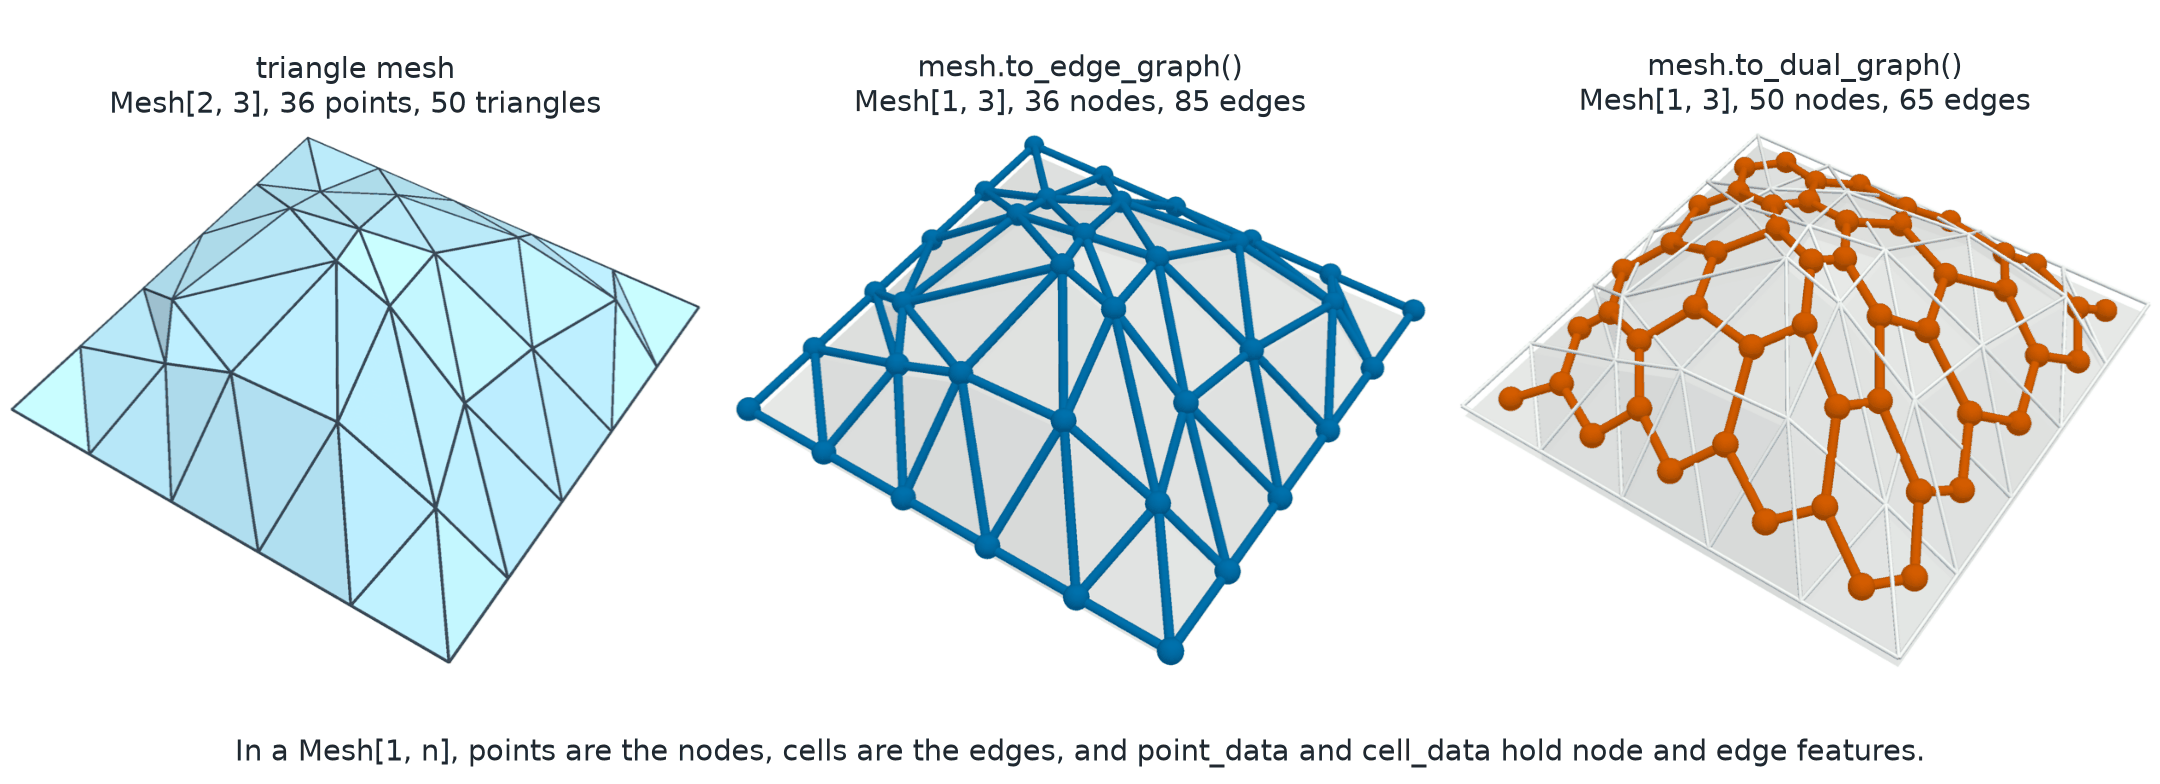

In [8]:
Image(filename="../../../docs/img/mesh/mesh_graphs.png", width=900)

The edge graph, `to_edge_graph()`, keeps the mesh points as nodes and the mesh
edges as edges. It suits data stored at points. The dual graph,
`to_dual_graph()`, puts a node at each cell centroid and joins two cells that
share a facet. It suits data stored at cells.

Some code uses a deep learning graph library only to hold node positions, an
edge list, and node and edge features. A `Mesh[1, n]` already holds all of
them, on the GPU, together with the geometry. The following table maps the
usual graph concepts to PhysicsNeMo-Mesh:

| Graph Concept | PhysicsNeMo-Mesh |
|---|---|
| Graph object | `Mesh[1, n]`, for example `isinstance(g, Mesh[1, 3])` |
| Node positions and node features | `g.points`, `g.point_data` |
| Edge list (undirected, each edge once) | `g.cells`, of shape `(n_edges, 2)` |
| Directed pairs for message passing | `g.get_point_to_points_adjacency().expand_to_pairs()` |
| Edge features | `g.cell_data`, with `g.cell_areas` as edge lengths and `g.cell_centroids` as midpoints |
| Graph-level attributes | `g.global_data` |
| Mesh graph, dual graph | `mesh.to_edge_graph()`, `mesh.to_dual_graph()` |
| k-nearest-neighbor graph | `knn` from `physicsnemo.nn.functional.neighbors`, wrapped in `Mesh(points=..., cells=...)` |
| Batching | `Mesh.merge(graphs)`, which offsets the edge indices |
| Augmentation | `rotate`, `translate`, `scale`, with `transform_point_data` and `transform_cell_data` |
| Subgraph, edge dropout | `slice_points`, `slice_cells` |
| Save, move to a device | `save` and `load`, `.to(device)` |

### Build a Graph

Both graphs of the sphere are `Mesh[1, 3]` objects, so every `Mesh` method
works on them. A k-nearest-neighbor graph is a `Mesh` too. Build its edges
from the indices that `knn` returns. The first neighbor of each point is the
point itself, so the example asks for one more neighbor and drops the first:

In [9]:
from physicsnemo.nn.functional.neighbors import knn

graph = sphere.to_edge_graph()
dual = sphere.to_dual_graph()
print(f"Edge graph is a Mesh[1, 3]: {isinstance(graph, Mesh[1, 3])}")
print(f"Edge graph: {graph.n_points} nodes, {graph.n_cells} edges")
print(f"Dual graph: {dual.n_points} nodes, {dual.n_cells} edges")

k = 6
neighbor_ids, _ = knn(sphere.points, sphere.points, k + 1)
node = torch.arange(sphere.n_points, device=device).repeat_interleave(k)
knn_graph = Mesh(
    points=sphere.points,
    cells=torch.stack([node, neighbor_ids[:, 1:].reshape(-1)], dim=1),
)
print(f"kNN graph: {knn_graph.n_points} nodes, {knn_graph.n_cells} edges")

Edge graph is a Mesh[1, 3]: True
Edge graph: 42 nodes, 120 edges
Dual graph: 80 nodes, 120 edges


kNN graph: 42 nodes, 252 edges


The kNN graph has one edge from each point to each of its six nearest points.
Two points that are each other's neighbors share two edges, one in each
direction.

### Edge Features from Geometry

Graph networks on meshes usually take the relative position of the two ends
of each edge, and its length, as edge features. Both come from the geometry.
The measure of a one-dimensional cell is its length, so `cell_areas` of a
`Mesh[1, n]` gives the edge lengths. Store the features in `cell_data`:

In [10]:
source, target = graph.cells.unbind(dim=-1)
graph.cell_data["dx"] = graph.points[target] - graph.points[source]
graph.cell_data["length"] = graph.cell_areas
print(graph)
print(
    "length equals |dx|:",
    torch.allclose(graph.cell_data["length"], graph.cell_data["dx"].norm(dim=-1)),
)

Mesh[n_manifold_dims=1, n_spatial_dims=3](n_points=42, n_cells=120)
    cell_data: {dx: (3,), length: ()}


length equals |dx|: True


Because the features live in the mesh, they follow it through the operations
of [Tutorial 4](tutorial_4_operations.ipynb). For example,
`graph.rotate(..., transform_cell_data={"dx": True})` rotates the edge vectors
with the nodes, and `slice_cells` drops edges together with their features.

### One Message-Passing Step

Message passing needs directed pairs. `expand_to_pairs()` turns the point
adjacency of the graph into one (source, target) pair for each neighbor.
Stacked, the pairs form the `(2, n_pairs)` edge index that graph neural network
code expects. Each edge appears twice, once in each direction:

In [11]:
adjacency = graph.get_point_to_points_adjacency()
source, target = adjacency.expand_to_pairs()
edge_index = torch.stack([source, target])
print(f"edge_index shape: {tuple(edge_index.shape)}, for {graph.n_cells} edges")
print(f"First pairs:\n{edge_index[:, :6]}")

edge_index shape: (2, 240), for 120 edges
First pairs:
tensor([[ 0,  0,  0,  0,  0,  1],
        [12, 13, 14, 15, 16, 12]], device='cuda:0')


The pairs are all that one step needs. This example computes, for each node,
the mean height of its neighbors, with one `index_add_` call and no loop. At
the top of the sphere, the neighbors are lower, so their mean is smaller than
the height of the node itself:

In [12]:
height = graph.points[:, 2]
neighbor_sum = torch.zeros_like(height).index_add_(0, source, height[target])
neighbor_mean = neighbor_sum / adjacency.counts
top = height.argmax()
print(f"Height of the top node: {height[top]:.4f}")
print(f"Mean height of its neighbors: {neighbor_mean[top]:.4f}")

Height of the top node: 1.0000
Mean height of its neighbors: 0.8229


For a model that works on edges, the cell adjacency of the graph joins edges
that share a node. This is the line graph. On this sphere, each edge touches
nine or ten other edges:

In [13]:
edge_neighbors = graph.get_cell_to_cells_adjacency()
counts, n_edges = edge_neighbors.counts.unique(return_counts=True)
print(f"Edges that touch each edge: {dict(zip(counts.tolist(), n_edges.tolist()))}")

Edges that touch each edge: {9: 60, 10: 60}


### What the Mesh Class Does Not Provide

The `Mesh` class covers mesh-based graph work. It does not replace a deep
learning graph library everywhere. It has none of the following:

- Built-in aggregation or message-passing layers. Write them with
  `index_add_`, as above.
- Heterogeneous graphs, with several types of nodes or edges.
- Neighbor-sampling data loaders for graphs that do not fit in memory.
- A batch-assignment vector. `Mesh.merge` returns one graph. Build the vector
  with `torch.repeat_interleave`.

Build the adjacency outside a function that you compile with
`torch.compile(fullgraph=True)`, and compile only the numerical step.
[Tutorial 9](tutorial_9_ml_integration.ipynb) trains a graph model on a mesh
and compiles mesh code.

## 4. Spatial Queries

A spatial query asks where a point lies in the mesh, for example to read the
solution at a sensor location. A brute-force test against every cell costs
O(n_cells) for each point. A bounding volume hierarchy (BVH) is a tree of boxes
around groups of cells. It rejects most cells with a few box tests, so a
query costs about O(log n_cells).

`BVH.from_mesh` builds the tree. `find_candidate_cells` returns, for each
query point, the cells whose bounding boxes contain it. The result is a short
list to test exactly.

In [14]:
mesh = unit_square.load(subdivisions=4, device=device)
bvh = BVH.from_mesh(mesh)

queries = torch.tensor(
    [
        [0.29, 0.29],  # inside one cell
        [0.5, 0.5],  # a mesh point, shared by six cells
        [0.3, 0.7],  # on an edge, shared by two cells
        [1.15, 1.15],  # outside the mesh
    ],
    device=device,
)
candidates = bvh.find_candidate_cells(queries)
print(f"Mesh: {mesh}")
print(f"Candidate cells per query: {candidates.counts.tolist()}")

Mesh: Mesh[n_manifold_dims=2, n_spatial_dims=2](n_points=289, n_cells=512)
Candidate cells per query: [2, 8, 2, 0]


`find_containing_cells` tests the candidates exactly and returns, for each
query, the first cell that contains it and its barycentric coordinates. The
barycentric coordinates are the weights of the cell's vertices that give the
point. A point outside the mesh gets cell `-1` and NaN coordinates. For a
point on an edge or at a mesh point, `find_all_containing_cells` returns every
cell that touches it.

In [15]:
cells, barycentric = find_containing_cells(mesh, queries, bvh=bvh)
print(f"First containing cell: {cells.tolist()}")
print(f"Barycentric coordinates:\n{barycentric}")
print(
    f"All containing cells: {find_all_containing_cells(mesh, queries, bvh=bvh).to_list()}"
)

First containing cell: [137, 239, 150, -1]
Barycentric coordinates:
tensor([[0.3600, 0.2800, 0.3600],
        [0.0000, 1.0000, 0.0000],
        [0.0000, 0.2000, 0.8000],
        [   nan,    nan,    nan]], device='cuda:0')
All containing cells: [[137], [239, 240, 241, 270, 271, 272], [150, 151], []]


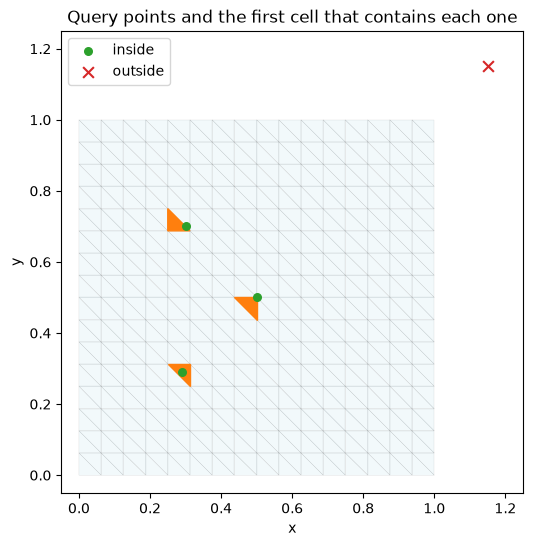

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
mesh.draw(ax=ax, show=False, alpha_cells=0.15, alpha_points=0.0)
for c in cells[cells >= 0].tolist():
    ax.fill(*mesh.points[mesh.cells[c]].cpu().T, color="tab:orange")
inside = cells >= 0
q = queries.cpu()
ax.scatter(*q[inside.cpu()].T, color="tab:green", s=30, zorder=3, label="inside")
ax.scatter(
    *q[~inside.cpu()].T, color="tab:red", marker="x", s=60, zorder=3, label="outside"
)
ax.set_xlim(-0.05, 1.25)
ax.set_ylim(-0.05, 1.25)
ax.legend(loc="upper left")
ax.set_title("Query points and the first cell that contains each one")
plt.show()

`find_nearest_cells` handles points outside the mesh. It returns the cell
whose centroid is closest to each point, and that centroid.

In [17]:
nearest, centroid = find_nearest_cells(mesh, torch.tensor([[1.5, 0.5]], device=device))
print(f"Nearest cell to (1.5, 0.5): {nearest.item()}, centroid {centroid[0]}")

Nearest cell to (1.5, 0.5): 495, centroid tensor([0.9792, 0.4792], device='cuda:0')


## 5. Sampling and Interpolation

Training on mesh points alone shows a model only a fixed set of locations.
Random points on the cells give new locations at every step, for data
augmentation or Monte Carlo integration. Interpolation gives the field values
at those points.

`sample_random_points_on_cells` returns one point in each listed cell. With no
argument, it samples one point in each cell. Repeat a cell index to sample that
cell several times.

In [18]:
torch.manual_seed(0)
square = unit_square.load(subdivisions=3, device=device)
samples = square.sample_random_points_on_cells()
print(f"One point per cell: {tuple(samples.shape)}")

repeated = square.sample_random_points_on_cells(
    cell_indices=torch.tensor([0, 0, 0, 1, 1])
)
print(f"From cells [0, 0, 0, 1, 1]:\n{repeated}")

One point per cell: (128, 2)
From cells [0, 0, 0, 1, 1]:
tensor([[0.0928, 0.0287],
        [0.0383, 0.0431],
        [0.0944, 0.0191],
        [0.0854, 0.1009],
        [0.0946, 0.0781]], device='cuda:0')


The `alpha` argument shapes the distribution inside each cell. It is the
concentration parameter of a Dirichlet distribution over the barycentric
coordinates. The default, 1.0, samples the cell uniformly. Larger values
concentrate the points near the centroid, and smaller values push them toward
the vertices and edges.

In [19]:
one_cell = torch.zeros(1000, dtype=torch.long, device=device)
centroid = square.cell_centroids[0]
for alpha in [0.3, 1.0, 5.0]:
    points = square.sample_random_points_on_cells(cell_indices=one_cell, alpha=alpha)
    print(
        f"alpha={alpha}: mean distance to the centroid {(points - centroid).norm(dim=-1).mean():.4f}"
    )

alpha=0.3: mean distance to the centroid 0.0566
alpha=1.0: mean distance to the centroid 0.0384
alpha=5.0: mean distance to the centroid 0.0182


`sample_data_at_points` returns the fields at arbitrary points, as a
TensorDict with one entry for each field. With `data_source="points"`, it
interpolates the point data linearly with the barycentric coordinates, so a
linear field such as T = x + y comes out exact. With `data_source="cells"`,
it returns the value of the containing cell. Points outside the mesh get NaN.

In [20]:
square.point_data["T"] = square.points.sum(dim=-1)
square.cell_data["cell_id"] = torch.arange(
    square.n_cells, dtype=torch.float32, device=device
)

points = torch.tensor([[0.27, 0.31], [0.6, 0.45], [1.5, 0.5]], device=device)
at_points = square.sample_data_at_points(points, data_source="points")
at_cells = square.sample_data_at_points(points, data_source="cells")
print(f"T, interpolated: {at_points['T']}")
print(f"T, exact:        {points.sum(dim=-1)}")
print(f"cell_id:         {at_cells['cell_id']}")

T, interpolated: tensor([0.5800, 1.0500,    nan], device='cuda:0')
T, exact:        tensor([0.5800, 1.0500, 2.0000], device='cuda:0')
cell_id:         tensor([36., 71., nan], device='cuda:0')


With `project_onto_nearest_cell=True`, every query point first moves to the
centroid of its nearest cell, and the result is the value at that centroid.
This also changes the values at the points inside the mesh. For (1.5, 0.5),
the closest boundary point is (1.0, 0.5), where T = 1.5, but the result is the
smaller value at a centroid. The option is meant for surfaces in 3D, where
query points lie slightly off the surface.

In [21]:
projected = square.sample_data_at_points(
    points, data_source="points", project_onto_nearest_cell=True
)
print(f"T, projected: {projected['T']}")

T, projected: tensor([0.5833, 1.0417, 1.4167], device='cuda:0')


The figure combines both steps: 2000 random points on the mesh, colored by
the interpolated value of f = sin(2πx) cos(2πy).

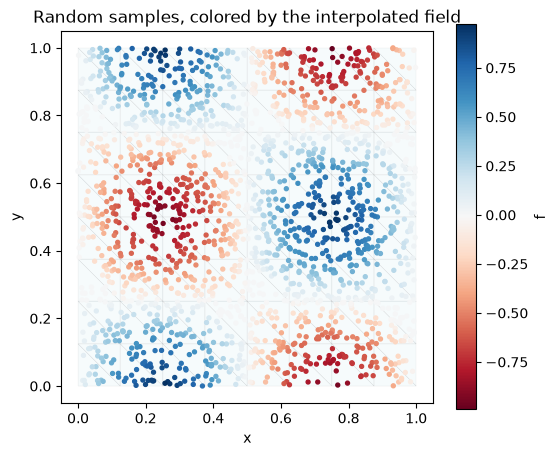

In [22]:
x, y = square.points[:, 0], square.points[:, 1]
square.point_data["f"] = torch.sin(2 * torch.pi * x) * torch.cos(2 * torch.pi * y)
cell_indices = torch.randint(0, square.n_cells, (2000,), device=device)
samples = square.sample_random_points_on_cells(cell_indices=cell_indices)
f_samples = square.sample_data_at_points(samples, data_source="points")["f"]

fig, ax = plt.subplots(figsize=(6, 5))
square.draw(ax=ax, show=False, alpha_cells=0.1, alpha_points=0.0)
scatter = ax.scatter(*samples.cpu().T, c=f_samples.cpu(), cmap="RdBu", s=8)
fig.colorbar(scatter, ax=ax, label="f")
ax.set_title("Random samples, colored by the interpolated field")
plt.show()

Each call above builds a BVH. To query the same mesh many times, build one
with `BVH.from_mesh(mesh)` and pass it as `bvh=`.

## 6. Signed Distance to a Surface

Models of flow around a body often take the distance to the body surface as an
input feature. `signed_distance_field` computes it for a closed triangle
surface in 3D. The distance is negative inside the surface and positive
outside. The function also returns the closest point on the surface and the
index of the nearest triangle. It runs on NVIDIA Warp, on a CPU or a GPU. For
a surface with holes, pass `use_sign_winding_number=True`, which computes the
sign from the generalized winding number and does not need a closed surface.

In [23]:
sphere = sphere_icosahedral.load(subdivisions=3, device=device)
queries = torch.tensor(
    [[0.0, 0.0, 0.0], [0.0, 0.0, 0.5], [0.0, 0.0, 1.5]], device=device
)
distance, closest, triangle = signed_distance_field(sphere, queries)
print(f"Signed distance: {distance}")
print(f"Closest points:\n{closest}")
print(f"Nearest triangles: {triangle.tolist()}")

Signed distance: tensor([-0.9955, -0.4980,  0.5000], device='cuda:0')
Closest points:
tensor([[0.3552, 0.0000, 0.9299],
        [0.0447, 0.0000, 0.9960],
        [0.0000, 0.0000, 1.0000]], device='cuda:0')
Nearest triangles: [1023, 1016, 996]


The triangles of the sphere lie slightly inside the unit sphere, so the
center is a little less than 1.0 from the surface.

## Summary

This tutorial covered the following points:

- `get_point_to_points_adjacency`, `get_point_to_cells_adjacency`,
  `get_cell_to_cells_adjacency`, and `get_cell_to_points_adjacency` return
  topological neighbors as an `Adjacency`.
- An `Adjacency` stores ragged lists as `offsets` and `indices`.
- The edge graph and the dual graph of any mesh are `Mesh[1, n]` objects.
  `cell_data` holds edge features, `expand_to_pairs()` gives the directed
  pairs, and `index_add_` passes messages along them.
- `BVH.from_mesh` speeds up point location. `find_containing_cells` and
  `find_all_containing_cells` use it. `find_nearest_cells` searches the cell
  centroids instead.
- `sample_random_points_on_cells` samples points in cells, and
  `sample_data_at_points` interpolates fields at any point.
- `signed_distance_field` gives the signed distance to a closed triangle
  surface.

## Next Steps

Continue with the following resources:

- **Next**: [Tutorial 7: Quality, Validation, and Repair](tutorial_7_quality_repair.ipynb)
  measures cell quality, finds duplicate points, holes, and inconsistent
  winding, and repairs them.
- API Reference:
  [neighbors](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/neighbors.html),
  [spatial](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/spatial.html),
  and [sampling](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/sampling.html).
- User Guide: [Using Meshes](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/using_mesh.html).